In [1]:
import base

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem1
import optimiser_new
from math import factorial
import pickle

C:\Users\muham\anaconda3\lib\site-packages\torch\__init__.py:696: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\tensor\python_tensor.cpp:453.)
  _C._set_default_tensor_type(t)


In [77]:
np.random.seed(123)

T = 2
Nt = 10_000
dt = T/Nt
nsims = 1000
eps = 2
x0 = 1
timesteps = np.linspace(0, T, num = (Nt+1))

X = np.zeros((Nt+1, nsims))
X[0, :] = x0

for i in range(Nt):
    X[i+1, :] = X[i, :]
    X[i+1, :] += X[i, :]**2*dt
    X[i+1, :] += eps*X[i, :]**2*np.random.randn(nsims)*np.sqrt(dt)

<ipython-input-77-0ba654745ff9>:16: RuntimeWarning: overflow encountered in square
  X[i+1, :] += X[i, :]**2*dt
<ipython-input-77-0ba654745ff9>:17: RuntimeWarning: overflow encountered in square
  X[i+1, :] += eps*X[i, :]**2*np.random.randn(nsims)*np.sqrt(dt)
<ipython-input-77-0ba654745ff9>:17: RuntimeWarning: invalid value encountered in add
  X[i+1, :] += eps*X[i, :]**2*np.random.randn(nsims)*np.sqrt(dt)


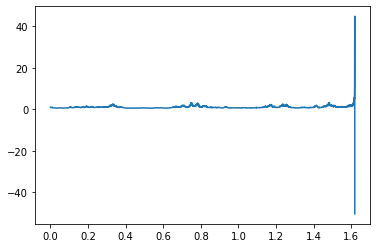

In [97]:
nsim = 50
tstop = 8095
#tstop = Nt+1
plt.plot(timesteps[:tstop], X[:tstop, nsim])

In [82]:
np.where(np.isnan(X[-1, :]))[0][0]

50